<a href="https://colab.research.google.com/github/NielsRogge/Transformers-Tutorials/blob/master/SegFormer/Fine_tune_SegFormer_on_custom_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In this notebook, we are going to fine-tune `SegFormerForSemanticSegmentation` from 'HuggingFace' on **Semantic-Drone** dataset. In semantic segmentation, the goal for the model is to label each pixel of an image with one of a list of predefined classes.

It will be needed to load the encoder of the model with weights pre-trained on an appropiate dataset, and fine-tune it together with the decoder head, which starts with randomly initialized weights.

In [3]:
''' Escribir el nombre de la prueba a realizar:
    sera usado para identificar el tensorboard y los modelos que genere '''
experiment_runname = "SDD_BIGex_4FINAL"

In [26]:
''' Escribir la dirección del Dataset a partir del directorio de ejecución: '''
#dataset_dir = '/home/chuyalex/workspace/drone-images-semantic-segmentation/semantic_drone_processed_dataset'
#trainset_dir = "/home/chuyalex/workspace/drone-images-semantic-segmentation/semantic_drone_processed_dataset/train"
#trainset_dir = "/home/chuyalex/workspace/drone-images-semantic-segmentation/semdrone_processdata_2/train"
#raw_dir = "/home/aisyslab/chuyalex/SemanticDroneDataset/Processed_1/train/img"
#lbl_dir = "~/chuyalex/SemanticDroneDataset/Processed_1/train/msk"
#valset_dir = "/home/chuyalex/workspace/drone-images-semantic-segmentation/semantic_drone_processed_dataset/val"
#valset_dir = "/home/chuyalex/workspace/drone-images-semantic-segmentation/semdrone_processdata_2/val"
#val_dir = "/home/aisyslab/chuyalex/SemanticDroneDataset/Processed_1/val/img"
#val_maks = "~/chuyalex/SemanticDroneDataset/Processed_1/val/msk"
#testset_dir = "/home/chuyalex/workspace/drone-images-semantic-segmentation/semantic_drone_processed_dataset/test"

# dataset_dir = "/home/chuyalex/workspace/drone-images-semantic-segmentation/semdrone_processdata_2"
dataset_dir = "C:/Users/embat/Datasets/ViVa-DATASET"

# train2val_ratio = 0.8
train2val_ratio = 0.9

In [5]:
''' Escribir la dirección del diccionario de clases del dataset: '''
#dict_dir = '~/chuyalex/SemanticDroneDataset/class_dict.csv'
# labeldict_dir = '/home/chuyalex/workspace/drone-images-semantic-segmentation/semantic_drone_dataset/training_set/gt/semantic/class_dict.csv'
labeldict_dir = "C:/Users/embat/Datasets/SemanticDroneDataset/class_dict.csv"

In [6]:
''' Escribir la dirección del JSON con la configuración del modelo: '''
json_dir = r"C:\Users\embat\Workspace\SegFormer\src\model.json"

In [34]:
''' En caso de retomar entrenamiento desde uno previamente guardado '''
#weight_fn = None
# pretrained = None
pretrained = "C:/Users/embat/Workspace/SegFormer/best_model_B5.pth"


## Define PyTorch dataset and dataloaders

Here we define a [custom PyTorch dataset](https://pytorch.org/tutorials/beginner/data_loading_tutorial.html). Each item of the dataset consists of an image and a corresponding segmentation map.

In [8]:
import os
import time
import json
from PIL import Image
#from PIL import ImageFile
#ImageFile.LOAD_TRUNCATED_IMAGES = True

In [10]:
%uv add matplotlib

Note: you may need to restart the kernel to use updated packages.


c:\Users\embat\Workspace\SegFormer\.venv\Scripts\python.exe: No module named uv


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [12]:
with open(json_dir) as f:
        model_json = json.load(f)

In [14]:
from torch.utils.data import Dataset
from torch.utils.tensorboard import SummaryWriter

In [15]:
writer = SummaryWriter(os.path.join(os.getcwd(),"runs", experiment_runname))

In [17]:
color_map = pd.read_csv(labeldict_dir, index_col=False, skipinitialspace=True)
color_map.columns = ["label", "R", "G", "B", "risk"]
#color_map.head()
label2id = {label: id for id, label in enumerate(color_map.label)}
id2label = {id: label for id, label in enumerate(color_map.label)}
id2color = {id: [R,G,B] for id, (R,G,B) in enumerate(zip(color_map.R, color_map.G, color_map.B))}
print(len(id2label))
print(id2label)
print(id2color)

24
{0: 'unlabeled', 1: 'paved-area', 2: 'dirt', 3: 'grass', 4: 'gravel', 5: 'water', 6: 'rocks', 7: 'pool', 8: 'vegetation', 9: 'roof', 10: 'wall', 11: 'window', 12: 'door', 13: 'fence', 14: 'fence-pole', 15: 'person', 16: 'dog', 17: 'car', 18: 'bicycle', 19: 'tree', 20: 'bald-tree', 21: 'ar-marker', 22: 'obstacle', 23: 'conflicting'}
{0: [0, 0, 0], 1: [128, 64, 128], 2: [130, 76, 0], 3: [0, 102, 0], 4: [112, 103, 87], 5: [28, 42, 168], 6: [48, 41, 30], 7: [0, 50, 89], 8: [107, 142, 35], 9: [70, 70, 70], 10: [102, 102, 156], 11: [254, 228, 12], 12: [254, 148, 12], 13: [190, 153, 153], 14: [153, 153, 153], 15: [255, 22, 96], 16: [102, 51, 0], 17: [9, 143, 150], 18: [119, 11, 32], 19: [51, 51, 0], 20: [190, 250, 190], 21: [112, 150, 146], 22: [2, 135, 115], 23: [255, 0, 0]}


In [18]:
''' RGB Label to Code Label '''
def ssmask_RGB2code(rgb_labels, id2color):

    rgb_labels = np.array(rgb_labels)
    code_labels = np.zeros((rgb_labels.shape[0], rgb_labels.shape[1]), dtype=np.uint8)
    for id, color in id2color.items():
        code_labels[(rgb_labels == color).all(axis=-1)] = id

    return code_labels

In [19]:
class SemanticSegmentationDataset(Dataset):
    """Image (semantic) segmentation dataset."""

    def __init__(self, root_dir, feature_extractor, train=True, proportion=0.8):
        """
        Args:
            root_dir (string): Root directory of the dataset containing the images + annotations.
            feature_extractor (SegFormerFeatureExtractor): feature extractor to prepare images + segmentation maps.
            train (bool): Whether to load "training" or "validation" images + annotations.
        """
        self.root_dir = root_dir
        self.feature_extractor = feature_extractor
        self.train = train

        #sub_path = "train_" if self.train else "val_"
        #self.img_dir = os.path.join(self.root_dir, sub_path + "images", "img")
        #self.img_dir = os.path.join(self.root_dir, "img")
        """self.img_dir = os.path.join(self.root_dir, "aug_images")"""
        self.img_dir = os.path.join(self.root_dir, "img")
        #self.ann_dir = os.path.join(self.root_dir, "msk")
        """self.ann_dir = os.path.join(self.root_dir, "aug_masks")"""
        self.ann_dir = os.path.join(self.root_dir, "msk")
        
        # read images
        image_file_names = []
        for root, dirs, files in os.walk(self.img_dir):
            image_file_names.extend(files)
        #self.images = sorted(image_file_names)
        """self.images = sorted(image_file_names)[:round(len(image_file_names)*proportion)] if train else sorted(image_file_names)[round(len(image_file_names)*proportion):]"""
        self.images = sorted(image_file_names)
        
        # read annotations
        annotation_file_names = []
        for root, dirs, files in os.walk(self.ann_dir):
            annotation_file_names.extend(files)
        #self.annotations = sorted(annotation_file_names)
        """if train:
            self.annotations = sorted(annotation_file_names)[:round(len(image_file_names)*proportion)]
        else:
            self.annotations = sorted(annotation_file_names)[round(len(image_file_names)*proportion):]"""
        self.annotations = sorted(annotation_file_names)
        
        #assert len(self.images) == len(self.annotations), "There must be as many images as there are segmentation maps"
        #for idx in len(self.images):    # TypeError: 'int' object is not iterable ... dah
        for idx in range(len(self.images)):
            assert self.images[idx].split('.')[-2] == self.annotations[idx].split('.')[-2], "Mask {} don't match Image {}".format(self.annotations[idx], self.images[idx])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        
        image = Image.open(os.path.join(self.img_dir, self.images[idx]))
        annotation = Image.open(os.path.join(self.ann_dir, self.annotations[idx]))
        annotation_2d = ssmask_RGB2code(annotation, id2color)

        # randomly crop + pad both image and segmentation map to same size
        #encoded_inputs = self.feature_extractor(image, segmentation_map, return_tensors="pt")
        
        # feature extractor will also reduce labels!
        encoded_inputs = self.feature_extractor(image, Image.fromarray(annotation_2d), return_tensors="pt")

        # remove batch dimension
        for k,v in encoded_inputs.items():
            encoded_inputs[k].squeeze_()

        return encoded_inputs

Let's initialize the training + validation datasets. Important: we initialize the feature extractor with `reduce_labels=True`, as the classes in ADE20k go from 0 to 150, with 0 meaning "background". However, we want the labels to go from 0 to 149, and only train the model to recognize the 150 classes (which don't include "background"). Hence, we'll reduce all labels by 1 and replace 0 by 255, which is the `ignore_index` of SegFormer's loss function.

In [21]:
from transformers import SegformerFeatureExtractor

c:\Users\embat\Workspace\SegFormer\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [25]:
#feature_extractor = SegformerFeatureExtractor(reduce_labels=True)
# https://huggingface.co/transformers/v4.12.5/model_doc/segformer.html
# * do_resize (bool, optional, defaults to True) – Whether to resize/rescale the input based on a certain image_scale.
# * keep_ratio (bool, optional, defaults to True) – Whether to keep the aspect ratio when resizing the input. Only has an effect if do_resize is set to True.
# * image_scale (float or int or Tuple[int]/List[int], optional, defaults to (2048, 512)) – 
#feature_extractor = SegformerFeatureExtractor(reduce_labels=True, image_scale=(768,512))
#feature_extractor = SegformerFeatureExtractor(reduce_labels=True, do_resize=True, keep_ratio=True, image_scale=4)
#feature_extractor = SegformerFeatureExtractor(reduce_labels=True, do_resize=False, keep_ratio=False, image_scale=4) # >>> torch.Size([2, 2000, 3000])
""" Más bien, el ancho y el alto están al revés ... igual no sé porqué salió eso, o sea, la imagen a la mitad :L ... """
#feature_extractor = SegformerFeatureExtractor(reduce_labels=True, do_resize=True, keep_ratio=False, image_scale=(1000, 1500))
feature_extractor = SegformerFeatureExtractor(reduce_labels=True, size=(512, 768))
# """ Respuesta en la siguiente celda """     # *comentario
# SegformerFeatureExtractor {...  "resample": 2,  "rescale_factor": 0.00392156862745098,  "size": {
#     "height": 512,
#     "width": 768
#   }
# }

#train_dataset = SemanticSegmentationDataset(root_dir=trainset_dir, feature_extractor=feature_extractor)
"""trainset = SemanticSegmentationDataset(root_dir=dataset_dir, feature_extractor=feature_extractor, train=True, proportion=train2val_ratio)"""
trainset = SemanticSegmentationDataset(root_dir=os.path.join(dataset_dir, "train"), feature_extractor=feature_extractor, train=True, proportion=train2val_ratio)
#valid_dataset = SemanticSegmentationDataset(root_dir=valset_dir, feature_extractor=feature_extractor, train=False)
"""valset = SemanticSegmentationDataset(root_dir=dataset_dir, feature_extractor=feature_extractor, train=False, proportion=train2val_ratio)"""
valset = SemanticSegmentationDataset(root_dir=os.path.join(dataset_dir, "val"), feature_extractor=feature_extractor, train=False)

#print("Number of training examples:", len(train_dataset))
print("Number of training images:   ", len(trainset))
#print("Number of validation examples:", len(valid_dataset))
print("Number of validation images: ", len(valset))

Number of training images:    9000
Number of validation images:  1000


Next, we define corresponding dataloaders.

In [27]:
from torch.utils.data import DataLoader

In [ ]:
#train_dataloader = DataLoader(train_dataset, batch_size=model_json['train_batch_size'], shuffle=True, num_workers=model_json['train_batch_size'])
#trainloader = DataLoader(trainset, batch_size=model_json['train_batch_size'], shuffle=True)     # *
# trainloader = DataLoader(trainset, batch_size=model_json['train_batch_size'], shuffle=True, num_workers=model_json["train_batch_size"])
trainloader = DataLoader(trainset, batch_size=4, shuffle=True, num_workers=0)

#valid_dataloader = DataLoader(valid_dataset, batch_size=model_json['val_batch_size'], num_workers=model_json['val_batch_size'])
#validloader = DataLoader(valset, batch_size=model_json['val_batch_size'])                       # *
# validloader = DataLoader(valset, batch_size=model_json['val_batch_size'], num_workers=model_json["val_batch_size"])
validloader = DataLoader(valset, batch_size=8, num_workers=0)

print(trainloader.num_workers, validloader.num_workers)
""" * Se tardó el doble de tiempo en entrenar el modelo B0, no sé si el num_workers tuvo algo que ver """
#train_dataloader.batch_size, valid_dataloader.batch_size
trainloader.batch_size, validloader.batch_size

0 0


(2, 4)

## Define the model

Here we load the model, and equip the encoder with weights pre-trained on ImageNet-1k (we take the smallest variant, `nvidia/mit-b0` here, but you can take a bigger one like `nvidia/mit-b5` from the [hub](https://huggingface.co/models?other=segformer)). We also set the `id2label` and `label2id` mappings, which will be useful when performing inference.

In [29]:
from transformers import SegformerForSemanticSegmentation
#from huggingface_hub import cached_download, hf_hub_url

In [30]:
# define model
model = SegformerForSemanticSegmentation.from_pretrained(#"nvidia/mit-b0",   # 188MiB,   val=1660MiB,    train=2172MiB
                                                         "nvidia/mit-b5",   # 508MiB,   val=3706MiB,    train=9724MiB
                                                         #"nvidia/segformer-b5-finetuned-cityscapes-1024-1024",
                                                         # RuntimeError: Error(s) in loading state_dict for SegformerForSemanticSegmentation:
                                                         #size mismatch for decode_head.classifier.weight: copying a param with shape torch.Size([19, 768, 1, 1]) from checkpoint, the shape in current model is torch.Size([24, 768, 1, 1]).
                                                         #size mismatch for decode_head.classifier.bias: copying a param with shape torch.Size([19]) from checkpoint, the shape in current model is torch.Size([24]).
                                                         #You may consider adding `ignore_mismatched_sizes=True` in the model `from_pretrained` method.
                                                         num_labels=24,
                                                         id2label=id2label, 
                                                         label2id=label2id,
)

Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b5 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.linear_c.3.proj.weight', 'decode_head.linear_fuse.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


## Fine-tune the model

Here we fine-tune the model in native PyTorch, using the AdamW optimizer. We use the same learning rate as the one reported in the [paper](https://arxiv.org/abs/2105.15203).

It's also very useful to track metrics during training. For semantic segmentation, typical metrics include the mean intersection-over-union (mIoU) and pixel-wise accuracy. These are available in the Datasets library. We can load it as follows:

In [31]:
import torch
#import torch.nn as nn
from torch import nn
#from tqdm.notebook import tqdm

In [36]:
#from datasets import load_metric
#from torchmetrics.classification import MulticlassAccuracy
#from sklearn.metrics import accuracy_score
from sklearn.metrics import balanced_accuracy_score

In [37]:
# Epoch 1:
#/home/chuyalex/workspace/SegFormer/.venv/lib/python3.8/site-packages/sklearn/metrics/_classification.py:2399: UserWarning: y_pred contains classes not in y_true
#  warnings.warn("y_pred contains classes not in y_true")
#|░░░░░░░░░░| Batch 1 > Loss : 3.2873, Bal Acc : 0.0025

# https://stackoverflow.com/questions/879173/how-to-ignore-deprecation-warnings-in-python
# Nada más que hay que cambiarle el tipo de Warning que queremos silenciar ... échele coco ahí

import warnings
#warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)

In [33]:
# define optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=0.00006)

# define loss function
loss_fn = nn.CrossEntropyLoss()

# move model to GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

SegformerForSemanticSegmentation(
  (segformer): SegformerModel(
    (encoder): SegformerEncoder(
      (patch_embeddings): ModuleList(
        (0): SegformerOverlapPatchEmbeddings(
          (proj): Conv2d(3, 64, kernel_size=(7, 7), stride=(4, 4), padding=(3, 3))
          (layer_norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        )
        (1): SegformerOverlapPatchEmbeddings(
          (proj): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
          (layer_norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        )
        (2): SegformerOverlapPatchEmbeddings(
          (proj): Conv2d(128, 320, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
          (layer_norm): LayerNorm((320,), eps=1e-05, elementwise_affine=True)
        )
        (3): SegformerOverlapPatchEmbeddings(
          (proj): Conv2d(320, 512, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
          (layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)

In [42]:
#run_epoch = model_json['epochs']
epoch = None
running_time = 0
best_loss = float('inf')
if pretrained is not None:
    if os.path.isfile(pretrained):
        print("Loading checkpoint '{}'".format(pretrained))
        checkpoint = torch.load(pretrained, weights_only=False)
        # model.load_state_dict(checkpoint['state_dict'])
        model.load_state_dict(checkpoint['model_state'])
        # optimizer.load_state_dict(checkpoint['optimizer'])
        optimizer.load_state_dict(checkpoint['optimizer_state'])
        epoch = checkpoint['epoch']
        # best_loss = checkpoint['loss']
        # best_loss = checkpoint['best_loss']
        running_time = checkpoint['running_time']
        print("Loaded checkpoint '{}' (epoch {})".format(pretrained, checkpoint['epoch']))
    else:
        print("No checkpoint found at '{}'. Will create new checkpoint.".format(pretrained))
else:
    print("Starting new checkpoint.".format(pretrained))
    #pretrained = os.path.join(os.getcwd(), "runs", experiment_runname + "_EOTcheckpoint_{}.pth.tar".format(datetime.now().strftime("%Y%m%d_%H%M%S")))
    # pretrained = os.path.join(os.getcwd(), "runs", experiment_runname + "_EOTcheckpoint_{}.pth.tar")
    pretrained = os.path.join(os.getcwd(), "runs", experiment_runname, "eot_model_at_{}e.pth.tar".format(model_json["epochs"]))

Loading checkpoint 'C:/Users/embat/Workspace/SegFormer/best_model_B5.pth'
Loaded checkpoint 'C:/Users/embat/Workspace/SegFormer/best_model_B5.pth' (epoch 14)


In [29]:
''' Para ir modificando el batch para aprovechar lo más posible el uso de GPU '''
# with open(json_dir) as f:
#         model_json = json.load(f)
# #train_dataloader = DataLoader(train_dataset, batch_size=model_json['train_batch_size'], shuffle=True, num_workers=model_json['train_batch_size'])
# train_dataloader = DataLoader(train_dataset, batch_size=model_json['train_batch_size'], shuffle=True)
# #valid_dataloader = DataLoader(valid_dataset, batch_size=model_json['val_batch_size'], num_workers=model_json['val_batch_size'])
# valid_dataloader = DataLoader(valid_dataset, batch_size=model_json['val_batch_size'])
# train_dataloader.batch_size, valid_dataloader.batch_size

""" Ya no sirve mucho este bloque pues cuando explota la RAM del GPU tengo que reiniciar el programa para que el espacio se libere """
# Hay que investigar bien lo de tener limpio ese espacio despues de cada prueba de memoria de GPU

(2, 4)

In [51]:
''' Generate Statictis at Epoch 0 '''
sum_valoss = 0.0
sum_valacc = 0.0

t0_e = time.time()

model.eval()
with torch.no_grad():
    for j, data in enumerate(validloader, 1):
        images = data["pixel_values"].to(device)
        gtruth = data["labels"].to(device)

        outputs = model(pixel_values=images, labels=gtruth)
        loss, logits = outputs.loss, outputs.logits

        upsampled_logits = nn.functional.interpolate(logits, size=gtruth.shape[-2:], mode="bilinear", align_corners=False)
        predicted = upsampled_logits.argmax(dim=1)

        accuracy = balanced_accuracy_score(gtruth.cpu().numpy().flatten(), predicted.cpu().numpy().flatten())

            
        if device == 'cuda':
            torch.cuda.empty_cache()

        sum_valoss += loss.item()
        sum_valacc += accuracy

        print('|{}| Batch {} > Loss : {:.4f}, Bal Acc : {:.4f}'.format(int(j*10/len(validloader))*"█"+(10-int(j*10/len(validloader)))*"▒", j, loss.item(), accuracy), end='\r')

print('|{}| Batch {} > Loss : {:.4f}, Bal Acc : {:.4f}'.format(int(j*10/len(validloader))*"█"+(10-int(j*10/len(validloader)))*"▒", j, loss.item(), accuracy))
print('Epoch {} Validation Average > Loss : {:.4f}, Bal Acc : {:.4f}'.format(0, (sum_valoss / j), (sum_valacc / j)))
print("Epoch {} completed in {}.".format(0, time.strftime("%Hh %Mm %Ss", time.gmtime(time.time() - t0_e))), end='\n')
            
writer.add_scalar('Validation_Loss', sum_valoss / j, 0)
writer.add_scalar('Validation_Accuracy', sum_valacc / j, 0)

|██████████| Batch 250 > Loss : 8.6241, Bal Acc : 0.00237
Epoch 0 Validation Average > Loss : 9.2783, Bal Acc : 0.0084
Epoch 0 completed in 01h 28m 23s.


In [28]:
t0 = time.time()

#for i in range(epoch + 1 if epoch is not None else 1, m_param["epochs"]):
for i in range(epoch + 1 if epoch is not None else 1, model_json["epochs"] + 1):
    print('Epoch {}:'.format(i))
    
    t0_e = time.time()

    sum_trainloss = 0.0
    sum_trainacc = 0.0

    model.train()
    #for j, data in enumerate(trainloader, 1):
    #for j, data in enumerate(train_dataloader, 1):
    for j, data in enumerate(trainloader, 1):
        #images, labels = data
        #if cuda_available:
        #  images = images.cuda()
        #  labels = labels.cuda()
        #images = data[0].to(device)
        #gtruth = data[1].to(device)
        images = data["pixel_values"].to(device)
        gtruth = data["labels"].to(device)
        #print(gtruth.shape())   # TypeError: 'torch.Size' object is not callable
        #print(gtruth.size())
        
        
        optimizer.zero_grad()
        #output = model(images)
        #output = SemanticSegmentationModel.posprocess(output)
        outputs = model(pixel_values=images, labels=gtruth)
        #loss = loss_fn(output, labels)
        #loss = criterion(output, gtruth)
        loss, logits = outputs.loss, outputs.logits
        loss.backward()
        optimizer.step()

        upsampled_logits = nn.functional.interpolate(logits, size=gtruth.shape[-2:], mode="bilinear", align_corners=False)
        predicted = upsampled_logits.argmax(dim=1)

        #accuracy = balanced_accuracy_score(SemanticSegmentationModel.premetricproccess(output), gtruth.cpu().numpy().flatten())
        #print(gtruth.numpy().shape(), predicted.numpy().shape())                # TypeError: can't convert cuda:0 device type tensor to numpy. Use Tensor.cpu() to copy the tensor to host memory first.
        #print(gtruth.cpu().numpy().shape(), predicted.cpu().numpy().shape())    # TypeError: 'tuple' object is not callable
        #print(len(gtruth.cpu().numpy().flatten()), len(predicted.cpu().numpy().flatten()))
        accuracy = balanced_accuracy_score(gtruth.cpu().numpy().flatten(), predicted.cpu().numpy().flatten())
        
        if device == 'cuda':
            torch.cuda.empty_cache()

        sum_trainloss += loss.item()
        sum_trainacc += accuracy

        #print('|{}| Batch {} > Loss : {:.4f}, Bal Acc : {:.4f}'.format(int(j*10/len(train_dataloader))*"▓"+(10-int(j*10/len(train_dataloader)))*"░", j, loss.item(), accuracy), end='\r')
        print('|{}| Batch {} > Loss : {:.4f}, Bal Acc : {:.4f}'.format(int(j*10/len(trainloader))*"▓"+(10-int(j*10/len(trainloader)))*"░", j, loss.item(), accuracy), end='\r')
        #break

    #print('|{}| Batch {} > Loss : {:.4f}, Bal Acc : {:.4f}'.format(int(j*10/len(train_dataloader))*"▓"+(10-int(j*10/len(train_dataloader)))*"░", j, loss.item(), accuracy))
    print('|{}| Batch {} > Loss : {:.4f}, Bal Acc : {:.4f}'.format(int(j*10/len(trainloader))*"▓"+(10-int(j*10/len(trainloader)))*"░", j, loss.item(), accuracy))
    print('Epoch {} Train Average > Loss : {:.4f}, Bal Acc : {:.4f}'.format(i, (sum_trainloss / j), (sum_trainacc / j)), end='\n')
        
    writer.add_scalar('Training_Loss', sum_trainloss / j, i)
    writer.add_scalar('Training_Accuracy', sum_trainacc / j, i)
    

    ''' ========== Validation ========== '''
    sum_valoss = 0.0
    sum_valacc = 0.0

    model.eval()
    with torch.no_grad():
        #for j, data in enumerate(valid_dataloader, 1):
        for j, data in enumerate(validloader, 1):
            #images, labels = data
            #if cuda_available:
            #    images = images.cuda()
            #    labels = labels.cuda()
            #images = data[0].to(device)
            #gtruth = data[1].to(device)
            images = data["pixel_values"].to(device)
            gtruth = data["labels"].to(device)
            #print(gtruth.size())

            #output = model(images)
            #output = SemanticSegmentationModel.posprocess(output)
            outputs = model(pixel_values=images, labels=gtruth)
            #loss = loss_fn(output, labels)
            #loss = criterion(output, gtruth)
            loss, logits = outputs.loss, outputs.logits

            upsampled_logits = nn.functional.interpolate(logits, size=gtruth.shape[-2:], mode="bilinear", align_corners=False)
            predicted = upsampled_logits.argmax(dim=1)

            #accuracy = balanced_accuracy_score(SemanticSegmentationModel.premetricproccess(output), gtruth.cpu().numpy().flatten())
            #print(len(gtruth.cpu().numpy().flatten()), len(predicted.cpu().numpy().flatten()))
            #accuracy = balanced_accuracy_score(gtruth.cpu().numpy().flatten(), upsampled_logits.cpu().numpy().flatten())        # ValueError: Found input variables with inconsistent numbers of samples: [1048576, 25165824]
            """ Ah... que menso, no era upsampled_logits, era el predicted
             ... igual no entiendo porque las medidas de las máscaras en Training fueron 524288 524288 y en Validation subieron a 1048576 1048576
             pero ahorita no tengo tiempo de revisarlo ... """
            # Ah sí, ya sé porqué ... es el batch X.X todo menso, pero bueno, ya quedó
            # Training genera torch.Size([2, 512, 512]) y Validation torch.Size([4, 512, 512])
            accuracy = balanced_accuracy_score(gtruth.cpu().numpy().flatten(), predicted.cpu().numpy().flatten())

        
            if device == 'cuda':
                torch.cuda.empty_cache()

            sum_valoss += loss.item()
            sum_valacc += accuracy

            #print('Val Loss at {} mini-batch: {}'.format(j, loss.item() / trainloader.batch_size))
            #print('Val Acc at {} mini-batch: {}'.format(j, accuracy / trainloader.batch_size))
            #print('|{}| Batch {} > Loss : {:.4f}, Bal Acc : {:.4f}'.format(int(j*10/len(valid_dataloader))*"█"+(10-int(j*10/len(valid_dataloader)))*"▒", j, loss.item(), accuracy), end='\r')
            print('|{}| Batch {} > Loss : {:.4f}, Bal Acc : {:.4f}'.format(int(j*10/len(validloader))*"█"+(10-int(j*10/len(validloader)))*"▒", j, loss.item(), accuracy), end='\r')
            #break

    #print('Average validation loss @ epoch: {}'.format((sum_valloss / (j * trainloader.batch_size))))
    #print('Average validation accuracy @ epoch: {}'.format((sum_valacc / (j * trainloader.batch_size))))
    #print('|{}| Batch {} > Loss : {:.4f}, Bal Acc : {:.4f}'.format(int(j*10/len(valid_dataloader))*"█"+(10-int(j*10/len(valid_dataloader)))*"▒", j, loss.item(), accuracy))
    print('|{}| Batch {} > Loss : {:.4f}, Bal Acc : {:.4f}'.format(int(j*10/len(validloader))*"█"+(10-int(j*10/len(validloader)))*"▒", j, loss.item(), accuracy))
    print('Epoch {} Validation Average > Loss : {:.4f}, Bal Acc : {:.4f}'.format(i, (sum_valoss / j), (sum_valacc / j)))
    #print(t0-time.time(), j)
    #print("Epoch {} completed in {}.".format(i, time.strftime("%Hh %Mm %Ss", time.gmtime(time.time() - t0))), end='\n\n')   # Me equivoqué de tiempo
    print("Epoch {} completed in {}.".format(i, time.strftime("%Hh %Mm %Ss", time.gmtime(time.time() - t0_e))), end='\n\n')
    #exit()
        
    #writer.add_scalar('Validation_Loss', sum_valloss/(valloader.batch_size * j), i)
    #writer.add_scalar('Validation_Accuracy', sum_valacc/(valloader.batch_size * j), i)
    writer.add_scalar('Validation_Loss', sum_valoss / j, i)
    writer.add_scalar('Validation_Accuracy', sum_valacc / j, i)
        

    if sum_valoss / j < best_loss:
        print("[Metrics improved from {} to {}: updating Best Model state for {}]".format(best_loss, sum_valoss/j, experiment_runname))
        best_loss = sum_valoss / j
        torch.save({
            'epoch': i,
            'running_time': time.time() - t0,
            'model_state': model.state_dict(),
            'optimizer_state': optimizer.state_dict(),
            #'loss_fn': criterion,
            'loss_fn': loss_fn,
            }, os.path.join(os.getcwd(),'runs', experiment_runname, 'best_model.pth'))

    #break

# print("Training complete at {}.".format(time.time() - t0).strftime("%H:%M:%S"))
# https://www.reddit.com/r/sysadmin/comments/afh059/anydesk_keyboard_problem/#DesuThorr
# print(time.strftime("%H:%M:%S", time.gmtime(time.time() - t0)))
# https://stackoverflow.com/questions/60133202/how-to-format-time-time-using-strftime-in-python
#print("Training complete at {}.".format(time.strftime("%H:%M:%S", time.gmtime(time.time() - t0))))
# print("Training complete at {}.".format(time.strftime("%Hh %Mm %Ss", time.gmtime(time.time() - t0))))
print("Training complete at {}. \nSaving last model.".format(time.strftime("%Hh %Mm %Ss", time.gmtime(running_time + time.time() - t0))))
# print("Training complete at {}. \nSaving last model.".format(time.strftime("%Hh %Mm %Ss", time.gmtime(time.time() - t0))))
#save_checkpoint({'epoch': run_epoch, 'state_dict': model.state_dict(), 'optimizer' : optimizer.state_dict()}, weight_fn)
torch.save({'epoch': i, 'running_time': running_time + (time.time() - t0), 'model_state': model.state_dict(), 'optimizer_state': optimizer.state_dict(), 'loss_fn': criterion,}, pretrained)
# torch.save({'epoch': i, 'running_time': (time.time() - t0), 'model_state': model.state_dict(), 'optimizer_state': optimizer.state_dict(), 'loss_fn': loss_fn,}, pretrained)

Epoch 1:
|▓▓▓▓▓▓▓▓▓▓| Batch 640 > Loss : 0.6384, Bal Acc : 0.4551
Epoch 1 Train Average > Loss : 0.7238, Bal Acc : 0.5092
|██████████| Batch 80 > Loss : 0.1894, Bal Acc : 0.5873
Epoch 1 Validation Average > Loss : 0.3002, Bal Acc : 0.5646
Epoch 1 completed in 00h 31m 53s.

[Metrics improved from inf to 0.30018670968711375: updating Best Model state for SDD_BIGexperiment_3]
Epoch 2:
|▓▓▓▓▓▓▓▓▓▓| Batch 640 > Loss : 0.4402, Bal Acc : 0.4840
Epoch 2 Train Average > Loss : 0.3534, Bal Acc : 0.6229
|██████████| Batch 80 > Loss : 0.1765, Bal Acc : 0.5586
Epoch 2 Validation Average > Loss : 0.2879, Bal Acc : 0.6053
Epoch 2 completed in 00h 31m 22s.

[Metrics improved from 0.30018670968711375 to 0.28792431866750123: updating Best Model state for SDD_BIGexperiment_3]
Epoch 3:
|▓▓▓▓▓▓▓▓▓▓| Batch 640 > Loss : 0.2737, Bal Acc : 0.7481
Epoch 3 Train Average > Loss : 0.2522, Bal Acc : 0.6622
|██████████| Batch 80 > Loss : 0.1811, Bal Acc : 0.5665
Epoch 3 Validation Average > Loss : 0.2728, Bal Acc : 

NameError: name 'criterion' is not defined

In [29]:
# #modelo = 'SemanticDrone_mit-b0_v1'
# #torch.save(model, '/home/chuyalex/workspace/SegFormer/' + modelo)
# torch.save({'epoch': i, 'state_dict': model.state_dict(), 'optimizer' : optimizer.state_dict(), 'loss' : best_loss}, pretrained)
# print("Checkpoint saved at {}".format(pretrained))

""" Modelo anterior salvado correctamente ... no es necesario de guardar el final aparte. """
# El cálculo del bloque anterior señala que tomó 11h 58m y 35s, pero lo más probable es que haya sido 1 día y 11h y así ...
# Habrä que ver cómo se cambiar para que exprese los días en horas.
""" Esta vez sí ... """

#torch.save({'epoch': i, 'running_time': running_time + (time.time() - t0), 'model_state': model.state_dict(), 'optimizer_state': optimizer.state_dict(), 'loss_fn': loss_fn}, pretrained)
#torch.save({'epoch': i, 'running_time': (((15*60)+50)*60+21)*1000, 'model_state': model.state_dict(), 'optimizer_state': optimizer.state_dict(), 'loss_fn': loss_fn}, pretrained)
torch.save({'epoch': i, 'running_time': (((15*60)+50)*60+21), 'model_state': model.state_dict(), 'optimizer_state': optimizer.state_dict(), 'loss_fn': loss_fn}, pretrained)
print("Training complete at {}. \nSaving last model.".format(time.strftime("%Hh %Mm %Ss", time.gmtime(running_time + time.time() - t0))))

Training complete at 16h 31m 26s. 
Saving last model.


In [37]:
#print(time.strftime("%Hh %Mm %Ss", time.gmtime((((15*60)+50)*60+21)*1000)))     # 23h 10m 00s
#print(time.strftime("%Hh %Mm %Ss", time.gmtime(1)))                             # 00h 00m 01s
print(time.strftime("%Hh %Mm %Ss", time.gmtime(((15*60)+50)*60+21)))

15h 50m 21s


## Test

Finally, let's check whether the model has really learned something. Let's test the trained model on an image:

In [29]:
#image = Image.open(os.path.join(testset_dir, 'img/aug_4_598.jpg'))
image = Image.open(os.path.join(dataset_dir, "val/img", "aug_1_479.jpg"))
#map = Image.open(os.path.join(testset_dir, 'msk/aug_4_598.png'))
map = Image.open(os.paht.join(dataset_dir, "val/msk", "aug_1_479.png"))

In [30]:
# prepare the image for the model
encoding = feature_extractor(image, return_tensors="pt")
pixel_values = encoding.pixel_values.to(device)
print(pixel_values.shape)

# forward pass
model.eval()
outputs = model(pixel_values=pixel_values)

# logits are of shape (batch_size, num_labels, height/4, width/4)
logits = outputs.logits.cpu()
print(logits.shape)

# rescale logits to original image size
upsampled_logits = nn.functional.interpolate(logits,
                size=image.size[::-1], # (height, width)
                mode='bilinear',
                align_corners=False)

# apply argmax on the class dimension
seg = upsampled_logits.argmax(dim=1)[0]

# add background label back
seg_corrected = seg + 1
seg_corrected[seg_corrected == 255] = 0

classes_map = np.unique(seg_corrected).tolist()
#print(classes_map)
unique_classes = [id2label[id] for id in classes_map]
#print("Classes in this image:", unique_classes)
print("Classes in this image:", [i, j for (i, j) in zip(classes_map, unique_classes)])

torch.Size([1, 3, 512, 512])
torch.Size([1, 24, 128, 128])
[1, 2, 4, 8, 9, 10, 15, 22]
Classes in this image: ['paved-area', 'dirt', 'gravel', 'vegetation', 'roof', 'wall', 'person', 'obstacle']


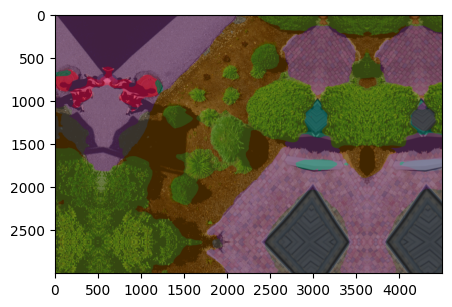

In [52]:
# create coloured map
color_seg = np.zeros((seg.shape[0], seg.shape[1], 3), dtype=np.uint8) # height, width, 3
for id in id2color:
    #print(id, id2color[id])
    #color_seg[seg == id, :] = id2color[id]
    color_seg[seg_corrected == id, :] = id2color[id]
    
# Show image + mask
img = np.array(image) * 0.5 + color_seg * 0.5
img = img.astype(np.uint8)

plt.figure(figsize=(5, 4))
plt.imshow(img)
plt.show()

Compare this to the ground truth segmentation map:

In [31]:
# convert map to NumPy array
map_array = np.array(map)
#map[map == 0] = 255 # background class is replaced by ignore_index
#map = map - 1 # other classes are reduced by one
#map[map == 254] = 255

grayscale = np.zeros((map_array.shape[0], map_array.shape[1]), dtype=np.uint8)
#grayscale.shape
for id in id2color:
    grayscale[(map_array == id2color[id]).all(axis=-1)] = id
    
classes_map = np.unique(grayscale).tolist()
#print(classes_map)
unique_classes = [id2label[id] for id in classes_map]
#print("Classes in this image:", unique_classes)
print("Classes in this image:", [i, j for (i, j) in zip(classes_map, unique_classes)])

[1, 2, 8, 9, 15, 22]
Classes in this image: ['paved-area', 'dirt', 'vegetation', 'roof', 'person', 'obstacle']


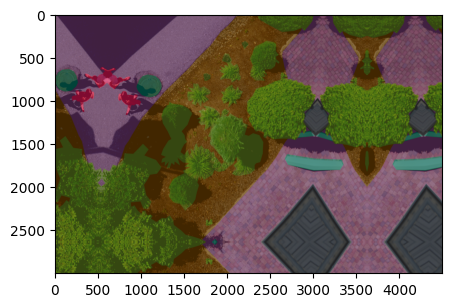

In [51]:
# create coloured map
#color_seg = np.zeros((grayscale.shape[0], grayscale.shape[1], 3), dtype=np.uint8) # height, width, 3
#for label, color in id2color.items():
#    color_seg[grayscale == label, :] = color

# Show image + mask
#img = np.array(image) * 0.5 + color_seg * 0.5
img = np.array(image) * 0.5 + map_array * 0.5
img = img.astype(np.uint8)

plt.figure(figsize=(5, 4))
plt.imshow(img)
plt.show()

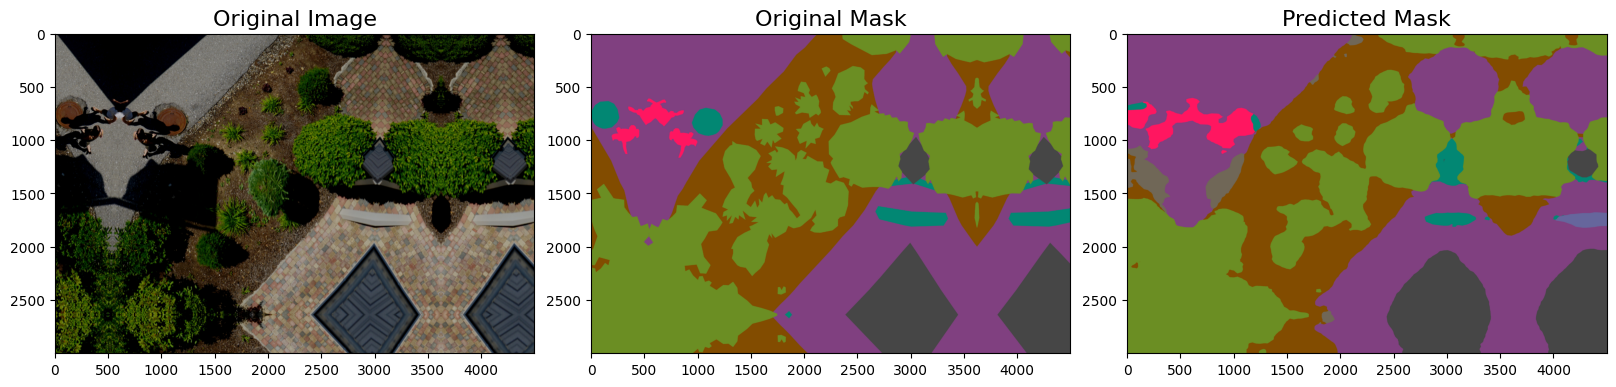

In [50]:
# f, ax = plt.subplots(1, 3, figsize=(16, 16), squeeze=True)
# plt.tight_layout(pad=0.2, w_pad=1.0, h_pad=0.01)
# fontsize = 16

# ax[0].imshow(np.array(image))
# ax[0].set_title('Original Image', fontsize=fontsize)

# ax[1].imshow(map)
# ax[1].set_title('Original Mask', fontsize=fontsize)

# ax[2].imshow(color_seg)
# ax[2].set_title('Predicted Mask', fontsize=fontsize)

# plt.show()

In [28]:
pretrained = "/home/chuyalex/workspace/SegFormer/runs/SDD_experimetrics_1/best_model.pth"
print("Loading checkpoint '{}'".format(pretrained))
checkpoint = torch.load(pretrained)
epoch = checkpoint['epoch']
model.load_state_dict(checkpoint['model_state_dict'])
optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
best_loss = checkpoint['loss']
print("Loaded checkpoint '{}' (epoch {})".format(pretrained, checkpoint['epoch']))

Loading checkpoint '/home/chuyalex/workspace/SegFormer/runs/SDD_experimetrics_1/best_model.pth'
Loaded checkpoint '/home/chuyalex/workspace/SegFormer/runs/SDD_experimetrics_1/best_model.pth' (epoch 10)


In [32]:
# #test_metric = load_metric("mean_iou", "f1")
# test_metric = load_metric("mean_iou")
# #test_iou = load_metric("mean_iou")
# #test_f1 = load_metric("f1")
# #test_acc = load_metric("accuracy")
#
# #test_metric.keys()

/home/chuyalex/workspace/SegFormer/.venv/lib/python3.8/site-packages/datasets/load.py:752: FutureWarning: The repository for mean_iou contains custom code which must be executed to correctly load the metric. You can inspect the repository content at https://raw.githubusercontent.com/huggingface/datasets/2.16.1/metrics/mean_iou/mean_iou.py
You can avoid this message in future by passing the argument `trust_remote_code=True`.
Passing `trust_remote_code=True` will be mandatory to load this metric from the next major release of `datasets`.
  warnings.warn(


AttributeError: 'MeanIoU' object has no attribute 'keys'

In [34]:
# #iou = test_iou._compute(num_labels=len(id2label), 
# #                            ignore_index=255,
# #                            reduce_labels=True,   # Veamos
# #                            predictions=seg_corrected,
# #                            references=grayscale)
# """f1 = test_f1._compute(#num_labels=len(id2label),     # TypeError: _compute() got an unexpected keyword argument 'num_labels'
#                         #ignore_index=255,      
#                         #reduce_labels=True,
#                         predictions=seg_corrected,
#                         references=grayscale,
#                         average=None)"""
# # ValueError: multiclass-multioutput is not supported
# """acc = test_acc._compute(#num_labels=len(id2label), 
#                             #ignore_index=255,
#                             #reduce_labels=True,
#                             predictions=seg_corrected,
#                             references=grayscale)"""
# metrics = test_metric._compute(num_labels=len(id2label), 
#                            ignore_index=255,
#                            reduce_labels=True,   # Veamos
#                            predictions=seg_corrected,
#                            references=grayscale)
#
# #loss = outputs.loss.cpu()
# #print('Test Loss: {}'.format(loss.item()))
# #print('Test Accuracy: {}'.format(iou["mean_accuracy"], f1["mean_accuracy"], acc["accuracy"]))
# print('Test Accuracy: {}'.format(metrics["mean_accuracy"]))
# print('Test IoU: {}'.format(metrics["mean_iou"]))
# #print('Test F1 score: {}'.format(f1["f1"]))
# metrics.keys()

Test Accuracy: 0.008868170762089001
Test IoU: 0.0013441807157237161


/home/chuyalex/.cache/huggingface/modules/datasets_modules/metrics/mean_iou/927b58f57da3f4b6e385e47d8a4b3947ee3f7cfcdba9b9359eba2ada2ed6b951/mean_iou.py:258: RuntimeWarning: invalid value encountered in divide
  iou = total_area_intersect / total_area_union
/home/chuyalex/.cache/huggingface/modules/datasets_modules/metrics/mean_iou/927b58f57da3f4b6e385e47d8a4b3947ee3f7cfcdba9b9359eba2ada2ed6b951/mean_iou.py:259: RuntimeWarning: invalid value encountered in divide
  acc = total_area_intersect / total_area_label


dict_keys(['mean_iou', 'mean_accuracy', 'overall_accuracy', 'per_category_iou', 'per_category_accuracy'])

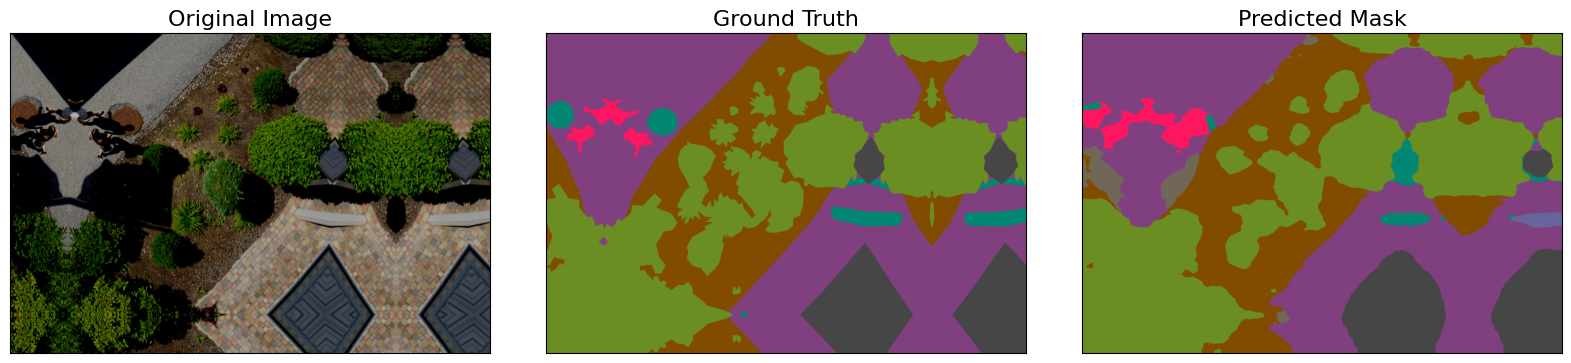

In [37]:
color_seg = np.zeros((seg.shape[0], seg.shape[1], 3), dtype=np.uint8) # height, width, 3
for id in id2color:
    #print(id, id2color[id])
    #color_seg[seg == id, :] = id2color[id]
    color_seg[seg_corrected == id, :] = id2color[id]

f, ax = plt.subplots(1, 3, figsize=(16, 16), squeeze=True)
plt.tight_layout(pad=0.2, w_pad=1.0, h_pad=0.01)
fontsize = 16

ax[0].imshow(np.array(image))
ax[0].tick_params(left = False, bottom = False, labelleft = False, labelbottom = False)
ax[0].set_title('Original Image', fontsize=fontsize)

ax[1].imshow(map)
ax[1].tick_params(left = False, bottom = False, labelleft = False, labelbottom = False)
ax[1].set_title('Ground Truth', fontsize=fontsize)

ax[2].imshow(color_seg)
ax[2].tick_params(left = False, bottom = False, labelleft = False, labelbottom = False)
ax[2].set_title('Predicted Mask', fontsize=fontsize)

plt.show()

In [189]:
#testset = 
# Ya esté el testset: se decidió que fuera el mismo que el de validación
testset = valset

array([ 1,  2,  3,  4,  8, 10, 13, 14, 15, 19, 22], dtype=uint8)

In [192]:
# #map
# grayscale

array([[ 8,  8,  8, ...,  4,  4,  4],
       [ 8,  8,  8, ...,  4,  4,  4],
       [ 8,  8,  8, ...,  4,  4,  4],
       ...,
       [13, 13, 13, ...,  3,  3,  3],
       [13, 13, 13, ...,  3,  3,  3],
       [13, 13, 13, ...,  3,  3,  3]], dtype=uint8)

Let's compute the metrics:

In [194]:
# # metric expects a list of numpy arrays for both predictions and references
# #metrics = metric.compute(predictions=[seg.numpy()], references=[map], num_labels=150, ignore_index=255)
# metrics = metric.compute(predictions=[seg.numpy()], references=[grayscale], num_labels=24, ignore_index=255)

: 

In [37]:
# metrics

dict_keys(['mean_iou', 'mean_accuracy', 'overall_accuracy', 'per_category_iou', 'per_category_accuracy'])

In [38]:
# import pandas as pd

# # print overall metrics
# for key in list(metrics.keys())[:3]:
#   print(key, metrics[key])

# # pretty-print per category metrics as Pandas DataFrame
# metric_table = dict()
# for id, label in id2label.items():
#     metric_table[label] = [
#                            metrics["per_category_iou"][id],
#                            metrics["per_category_accuracy"][id]
#     ]

# print("---------------------")
# print("per-category metrics:")
# pd.DataFrame.from_dict(metric_table, orient="index", columns=["IoU", "accuracy"])

mean_iou 0.1208766829944471
mean_accuracy 0.39513315771141927
overall_accuracy 0.8730268963745205
---------------------
per-category metrics:


,IoU,accuracy
wall,0.819543,0.908399
building,0.000000,0.000000
sky,0.884274,0.906800
floor,0.854250,0.964644
tree,0.687556,0.740283
...,...,...
shower,0.882019,0.897756
radiator,0.000000,NaN
glass,0.000000,NaN
clock,0.000000,0.000000


### Batch Test
Haciendo Test ahora sí de la manera correcta; estandarizando y usando las métricas de SciKit Learn

In [ ]:
#from sklearn.metrics import accuracy_score
#from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import jaccard_score
from sklearn.metrics import f1_score

In [ ]:
#color_map = pd.read_csv(labeldict_dir, index_col=False, skipinitialspace=True)
color_map.columns = ["label", "R", "G", "B", "risk"]
#label2id = {label: id for id, label in enumerate(color_map.label)}
#id2label = {id: label for id, label in enumerate(color_map.label)}
#id2color = {id: [R,G,B] for id, (R,G,B) in enumerate(zip(color_map.R, color_map.G, color_map.B))}
id2risk = {id: risk for id, risk in enumerate(color_map.risk)}
print(id2risk)

In [ ]:
''' SDD Labels to Risk Labels '''
#def reclass(rgb_labels, id2color, id2risk):
def sscode_reclass(labels, id2risk, id2color=None):

    if id2color is not None:
        code_labels = ssmask_RGB2code(labels, id2color)
        code_risk = np.zeros((code_labels.shape[0], code_labels.shape[1]), dtype=np.uint8)
        for id, risk in id2risk.items():
            code_risk[(code_labels == id).all(axis=-1)] = risk
    else:
        code_risk = np.zeros((labels.shape[0], labels.shape[1]), dtype=np.uint8)
        for id, risk in id2risk.items():
            code_risk[(labels == id)] = risk

    return code_risk

In [ ]:
code_label = ssmask_RGB2code(map, id2color)
code_risk = sscode_reclass(code_label, id2risk)
plt.imshow(code_risk)
plt.tick_params(left = False, bottom = False, labelleft = False, labelbottom = False)
plt.tight_layout(pad=0.0, w_pad=0.0, h_pad=0.0)

In [ ]:
''' obtener métricas directo '''
metrics = []

mean_acc = 0.0
mean_iou = 0.0
mean_f1 = 0.0
mean_ba = 0.0

model.eval()
with torch.no_grad():
    for j, data in enumerate(tqdm(test_dataloader), 1):
        images = data["pixel_values"].to(device)
        labels = data["labels"].to(device)
        
        outputs = model(pixel_values=images)
        
        upsampled_logits = nn.functional.interpolate(outputs.logits, size=labels.shape[-2:], mode="bilinear", align_corners=False)
        predicted = upsampled_logits.argmax(dim=1)

        # add background label back
        predicted = predicted + 1
        predicted[predicted == 256] = 0

        #predicted_color = np.zeros((predicted.shape[0], predicted.shape[1], 3), dtype=np.uint8) # height, width, 3
        #for id in id2color:
        #    predicted_color[predicted == id, :] = id2color[id]

        #map_ = labels.flatten()
        #pred_ = predicted.flatten()
        # TypeError: can't convert cuda:0 device type tensor to numpy. Use Tensor.cpu() to copy the tensor to host memory first.
        # Cuando estaba haciendo esto el GPU se trabó y no servía, pero igual hay que generalizar para que esté siempre al tiro.
        map_ = labels.flatten().cpu()
        pred_ = predicted.flatten().cpu()

        accuracy = accuracy_score(map_, pred_)
        balanced_acc = balanced_accuracy_score(map_, pred_)
        iou = jaccard_score(map_, pred_, average='macro')
        f1 = f1_score(map_, pred_, average='macro')

        metrics.append((accuracy, balanced_acc, iou, f1))

        mean_acc += accuracy
        mean_ba += balanced_acc
        mean_iou += iou
        mean_f1 += f1

#len(files)
print("Mean Accuracy: ", mean_acc / j)
print("Mean IoU:      ", mean_iou / j)
print("Mean F1 Score: ", mean_f1 / j)
print("Mean Bal Acc:  ", mean_ba / j)

metrics.append((mean_acc, mean_ba, mean_iou, mean_f1))
metrics.append((mean_acc / j, mean_ba / j, mean_iou / j, mean_f1 / j))

In [ ]:
for metric in metrics:
    print(metric)

In [ ]:
''' Generar imágenes a partir de predicción del modelo para evaluar métricas después '''
model.eval()
with torch.no_grad():
    for root, dirs, files in os.walk(os.path.join(testset_dir, 'img')):
        #print(files)
        #print(root)
        for file in files:
            #print(file.split('.')[0])
            image = Image.open(os.path.join(testset_dir, 'img', file))
            
            encoding = feature_extractor(image, return_tensors="pt")
            pixel_values = encoding.pixel_values.to(device)
            
            # forward pass
            outputs = model(pixel_values=pixel_values)

            # logits are of shape (batch_size, num_labels, height/4, width/4)
            # rescale logits to original image size
            upsampled_logits = nn.functional.interpolate(outputs.logits,
                    size=image.size[::-1], # (height, width)
                    mode='bilinear',
                    align_corners=False)
            
            # apply argmax on the class dimension
            predict = upsampled_logits.argmax(dim=1)[0].cpu()
            
            # add background label back
            predict = predict + 1
            predict[predict == 256] = 0

            # make color image
            predict_color = np.zeros((predict.shape[0], predict.shape[1], 3), dtype=np.uint8) # height, width, 3
            for id in id2color:
                predict_color[predict == id, :] = id2color[id]

            # save the image
            # https://pythonguides.com/python-save-an-image-to-file/
            #plt.imshow(predict_color)
            #plt.tick_params(left = False, bottom = False, labelleft = False, labelbottom = False)
            #plt.savefig(os.path.join(testset_dir, "pred", file.split('.')[0] + ".png"))
            '''Pero no -- guarda la imagen pero con borde y además son más pasos
            Además ... por alguna razón que no contabilicé pero es evidente, el
            proceso es mucho más rápido de la siguiente forma :o claramente más rápido:
                matplotlib llevaba 13 minutos con alrededor de 40 imágenes
                a PIL le tomó 3m12.4s terminar las 160 :v'''
            # https://iq.opengenus.org/display-numpy-array-as-image/
            # save the numpy array as image
            image = Image.fromarray(predict_color, "RGB")
            image.save(os.path.join(testset_dir, "pred_e20", file.split('.')[0] + ".png"))

In [ ]:
# https://builtin.com/data-science/python-list-files-in-directory
files = os.listdir(os.path.join(testset_dir, 'msk'))
#print(files)

metrics = []

mean_acc = 0.0
mean_iou = 0.0
mean_f1 = 0.0
mean_ba = 0.0
for file in files:
   #print(file)
   map = Image.open(os.path.join(testset_dir, 'msk', file))
   pred = Image.open(os.path.join(testset_dir, 'pred_e20', file))

   map = ssmask_RGB2code(np.array(map), id2color)
   pred = ssmask_RGB2code(np.array(pred), id2color)
   #print(map.shape, pred.shape)                        # (3000, 4500) (3000, 4500)
   #classes_map = np.unique(map).tolist()
   #print(classes_map)                                  # [0, 1, 3, 9, 15, 22]
   #unique_classes = [id2label[id] for id in classes_map]
   #print("Classes in this image:", unique_classes)     # Classes in this image: ['unlabeled', 'paved-area', 'grass', 'roof', 'person', 'obstacle']

   map_ = map.flatten()
   pred_ = pred.flatten()
   #print(map_.shape, pred_.shape)     # (13500000,) (13500000,)
   #break
   
   ##i = 0
   #cnfmx = []
   #for clase in range(1,24):
   #   #print(clase)
   #   #i += 1
   #   TP = 0
   #   TN = 0
   #   FP = 0
   #   FN = 0
   #   for px in range(map_.shape[0]):
   #      if map_[px] == pred_[px]:
   #         TP += 1
   #         elif map_ ...  # Mejor con sklearn :v después lo hago manual
   #
   ##print(clase, i)    # 22 | 23 23

   #metrics.append(confusion_matrix())
   accuracy = accuracy_score(map_, pred_)
   balanced_acc = balanced_accuracy_score(map_, pred_)
   iou = jaccard_score(map_, pred_, average='macro')
   f1 = f1_score(map_, pred_, average='macro')

   metrics.append((accuracy, balanced_acc, iou, f1))

   mean_acc += accuracy
   mean_ba += balanced_acc
   mean_iou += iou
   mean_f1 += f1

#len(files)
print("Mean Accuracy: ", mean_acc / len(files))
print("Mean IoU:      ", mean_iou / len(files))
print("Mean F1 Score: ", mean_f1 / len(files))
print("Mean Bal Acc:  ", mean_ba / len(files))

metrics.append((mean_acc, mean_ba, mean_iou, mean_f1))
metrics.append((mean_acc / len(files), mean_ba / len(files), mean_iou / len(files), mean_f1 / len(files)))

In [ ]:
"""Lomismoque el anterior¡?"""
#image_file_names = []
#for root, dirs, files in os.walk(os.path.join(testset_dir, "pred")):
#    image_file_names.extend(files)

risk_metrics = []

mean_acc = 0.0
mean_iou = 0.0
mean_f1 = 0.0
mean_ba = 0.0

for file in tqdm(files):
    ref = Image.open(os.path.join(testset_dir, "msk", file))
    pred = Image.open(os.path.join(testset_dir, "pred_e20", file))

    ref = ssmask_RGB2code(ref, id2color)
    #predict_risk = reclass(image, id2color, id2risk)
    pred = ssmask_RGB2code(pred, id2color)

    ref_risk = sscode_reclass(ref, id2risk).flatten()
    pred_risk = sscode_reclass(pred, id2risk).flatten()

    #image = Image.fromarray(predict_risk, "RGB")
    #image.save(os.path.join(testset_dir, "pred", file.split('.')[0] + ".png"))
    
    
    accuracy = accuracy_score(ref_risk, pred_risk)
    balanced_acc = balanced_accuracy_score(ref_risk, pred_risk)
    iou = jaccard_score(ref_risk, pred_risk, average='macro')
    f1 = f1_score(ref_risk, pred_risk, average='macro')

    #metrics.append((accuracy, balanced_acc, iou, f1))   # Dobabes
    risk_metrics.append((accuracy, balanced_acc, iou, f1))

    mean_acc += accuracy
    mean_ba += balanced_acc
    mean_iou += iou
    mean_f1 += f1


print("Mean Accuracy: ", mean_acc / len(files))
print("Mean IoU:      ", mean_iou / len(files))
print("Mean F1 Score: ", mean_f1 / len(files))
print("Mean Bal Acc:  ", mean_ba / len(files))

# Y esto no lo había corrido, entonces por esto y el dobabes de arriba, no salió el pretty-print
risk_metrics.append((mean_acc, mean_ba, mean_iou, mean_f1))
risk_metrics.append((mean_acc / len(files), mean_ba / len(files), mean_iou / len(files), mean_f1 / len(files)))

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

#np.arange(1, 24, dtype=np.uint) # array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23], dtype=uint64)
cnfmx = confusion_matrix(grayscale.flatten(), seg_corrected.flatten(), labels=np.arange(1,24))
#cnfmx.shape                     # (23, 23)
for clase in cnfmx:
    print(clase)

In [ ]:
#cnfmx_est = []
cnfmx_est = dict()
#for i, clase in enumerate(cnfmx):
#    print(i+1, clase)
for clase in range(1, 24):
    #print(i)
    TP = 0
    TN = 0
    FP = 0
    FN = 0
    #for i in np.arange(1,24):
    #    for j, cnt in enumerate(clase):
    #        if i == j:
    #            TP = cnt
    #        elif ... :v
    for i in range(0, 23):
        for j in range(0, 23):
            if i == clase-1 and j == clase-1:
                TP = cnfmx[i,j]
            elif i == clase-1:
                FN += cnfmx[i,j]
            elif j == clase-1:
                FP += cnfmx[i,j]
            else:
                TN += cnfmx[i,j]
    #cnfmx_est.append((TP, TN, FP, FN))
    cnfmx_est[clase] = [TP, TN, FP, FN]
#cnfmx_est
pd.DataFrame.from_dict(cnfmx_est, orient="index", columns=["TP", "TN", "FP", "FN"])

In [ ]:
# https://en.wikipedia.org/wiki/Sensitivity_and_specificity
metrics = dict()
#for key in list(cnfmx_est.keys())[:3]:
for key in list(cnfmx_est.keys()):
    #print(id2label[key])
    #print(cnfmx_est["TP"][key])     # KeyError: 'TP'
    #print(cnfmx_est[key][0])
    # RECALL | Hit Rate | True Positive Rate (TPR)
    sensitivity = cnfmx_est[key][0] / (cnfmx_est[key][0] + cnfmx_est[key][3])       # TP / (TP + FN)
    # Selectivity | True Negative Rate (TNR)
    specificity = cnfmx_est[key][1] / (cnfmx_est[key][1] + cnfmx_est[key][2])       # TN / (TN + FP)
    # Positive Predictive Value (PPV)
    precision = cnfmx_est[key][0] / (cnfmx_est[key][0] + cnfmx_est[key][2])         # TP / (TP + FP)
    # ...
    # Prevalence = P / (P + N) = (TP + FN) / (TP + TN + FP + FN)
    prevalence = (cnfmx_est[key][0] + cnfmx_est[key][3]) / (cnfmx_est[key][0] + cnfmx_est[key][1] + cnfmx_est[key][2] + cnfmx_est[key][3])
    # Accuracy = (TP + TN) / (TP + TN + FP + FN)
    accuracy = (cnfmx_est[key][0] + cnfmx_est[key][1]) / (cnfmx_est[key][0] + cnfmx_est[key][1] + cnfmx_est[key][2] + cnfmx_est[key][3])
    # Balanced Accuracy = (TPR + TNR) / 2
    balanced_acc = (sensitivity + specificity) / 2
    # F1 score: harmonic mean of precision and sensitivity = (2 * PPV * TPR) / (PPV + TPR)
    f1 = (2 * precision * sensitivity) / (precision + sensitivity)
    # https://www.v7labs.com/blog/intersection-over-union-guide
    # IoU = TP / (TP + FP + FN)
    # Threat Score (TR) | Critical Success Index (CSI)
    iou = cnfmx_est[key][0] / (cnfmx_est[key][0] + cnfmx_est[key][2] + cnfmx_est[key][3])
    
    # ========================

    metrics[id2label[key]] = [
                sensitivity,
                specificity,
                precision,
                prevalence,
                accuracy,
                balanced_acc,
                f1,
                iou
    ]
pd.DataFrame.from_dict(metrics, orient="index", columns=["Recall", "Specificity", "Precision", "Prevalence", 
                                                         "Accuracy", "Balanced Accuracy", "F1 Score", "IoU"])

In [ ]:
mean_acc = 0.0
mean_iou = 0.0
mean_f1 = 0.0
mean_ba = 0.0

nan = 0
for label, data in metrics.items():
    #print(data)
    mean_acc += data[4]
    #if data[7] is not None:
    # https://www.turing.com/kb/nan-values-in-python
    if not np.isnan(data[7]):
        #print(data[7])
        nan += 1
        mean_iou += data[7]
    if not np.isnan(data[6]):
        mean_f1 += data[6]
    if not np.isnan(data[5]):
        mean_ba += data[5]
print("Mean Accuracy: ", mean_acc / len(metrics))
print("Mean IoU:      ", mean_iou / nan)
print("Mean F1 Score: ", mean_f1 / nan)
print("Mean Bal Acc:  ", mean_ba / nan)

In [ ]:
#disp = ConfusionMatrixDisplay(confusion_matrix=cnfmx, display_labels=id2label)
# ValueError: The number of FixedLocator locations (23), usually from a call to set_ticks, does not match the number of labels (24).
# https://note.nkmk.me/en/python-dict-clear-pop-popitem-del/
#id2label.pop(0) # 'unlabeled'
#disp = ConfusionMatrixDisplay(confusion_matrix=cnfmx, display_labels=id2label.pop(0))
# ValueError: The number of FixedLocator locations (23), usually from a call to set_ticks, does not match the number of labels (9).
i = id2label.pop(0)
disp = ConfusionMatrixDisplay(confusion_matrix=cnfmx, display_labels=id2label)
disp.plot()
id2label[0] = i

In [ ]:
print(accuracy_score(grayscale.flatten(), seg_corrected.flatten()))
print(accuracy_score(grayscale.flatten(), seg_corrected.flatten(), normalize=False))

balanced_accuracy_score(grayscale.flatten(), seg_corrected.flatten())

#print(jaccard_score(grayscale.flatten(), seg_corrected.flatten()))
# ValueError: Target is multiclass but average='binary'. Please choose another average setting, one of [None, 'micro', 'macro', 'weighted'].
print(jaccard_score(grayscale.flatten(), seg_corrected.flatten(), average=None))
#print(jaccard_score(grayscale.flatten(), seg_corrected.flatten(), average=None, labels=np.arange(1,24)))
# UndefinedMetricWarning: Jaccard is ill-defined and being set to 0.0 in labels with no true or predicted samples. Use `zero_division` parameter to control this behavior.
#  _warn_prf(average, modifier, msg_start, len(result))
print(jaccard_score(grayscale.flatten(), seg_corrected.flatten(), average=None, labels=np.arange(1,24), zero_division=0.0))
print(jaccard_score(grayscale.flatten(), seg_corrected.flatten(), average='micro'))
print(jaccard_score(grayscale.flatten(), seg_corrected.flatten(), average='macro'))
#print(jaccard_score(grayscale.flatten(), seg_corrected.flatten(), average='samples'))
# ValueError: Samplewise metrics are not available outside of multilabel classification.

print(f1_score(grayscale.flatten(), seg_corrected.flatten(), average=None))
#print(f1_score(grayscale.flatten(), seg_corrected.flatten(), average=None, labels=np.arange(1,24), zero_division=0.00000001))
# InvalidParameterError: The 'zero_division' parameter of f1_score must be a float among {0.0, 1.0}, numpy.nan or a str among {'warn'}. Got 1e-08 instead.
#print(f1_score(grayscale.flatten(), seg_corrected.flatten(), average=None, labels=np.arange(1,24), zero_division=0.0001))
# InvalidParameterError: The 'zero_division' parameter of f1_score must be a float among {0.0, 1.0}, numpy.nan or a str among {'warn'}. Got 0.0001 instead.
#   Ah ya... las llaves es rango discreto
print(f1_score(grayscale.flatten(), seg_corrected.flatten(), average=None, labels=np.arange(1,24), zero_division=1.0))
print(f1_score(grayscale.flatten(), seg_corrected.flatten(), average='micro'))
print(f1_score(grayscale.flatten(), seg_corrected.flatten(), average='macro'))

# https://www.geeksforgeeks.org/reading-and-writing-json-to-a-file-in-python/
# https://stackabuse.com/reading-and-writing-json-to-a-file-in-python/
#i = np.arange(1,24)
#i = dict(i)
# TypeError: cannot convert dictionary update sequence element #0 to a sequence
# https://www.geeksforgeeks.org/how-to-convert-numpy-array-to-dictionary-in-python/
#i = dict(enumerate(i))
#i
#del metrics[0]
metrics = dict(enumerate(metrics, 1))
# https://www.digitalocean.com/community/tutorials/python-add-to-dictionary
metrics["Mean Accuracy"] = mean_acc / len(files)
metrics["Mean IoU"] = mean_iou / len(files)
metrics["Mean F1 Score"] = mean_f1 / len(files)
metrics["Mean Bal Acc"] = mean_ba / len(files)
with open(os.path.join(os.getcwd(),"runs", experiment_runname, "test_metrics.json"), "w") as outfile:
    json.dump(metrics, outfile, indent=4)
metrics

# https://stackoverflow.com/questions/8904694/how-to-normalize-a-2-dimensional-numpy-array-in-python-less-verbose
cm = np.array(([1,2,3,4],[1,3,2,4],[2,4,3,1],[4,3,2,1]))
print(cm.sum(axis=1))
#print(cm.sum(axis=1)[:, np.newaxis])
print(cm.sum(axis=1, keepdims=True))    # Sí, es lo mismo
cm = cm / cm.sum(axis=1)[:, np.newaxis]
print(cm)

In [ ]:
cnfmxs = []

#print(i for i in id2risk)
total_cm = np.zeros((6,6))

for file in tqdm(files):
    ref = Image.open(os.path.join(testset_dir, "msk", file))
    pred = Image.open(os.path.join(testset_dir, "pred_e20", file))

    ref = ssmask_RGB2code(ref, id2color)
    pred = ssmask_RGB2code(pred, id2color)

    ref_risk = sscode_reclass(ref, id2risk).flatten()
    pred_risk = sscode_reclass(pred, id2risk).flatten()

    
    cm = confusion_matrix(ref_risk, pred_risk, labels=np.arange(0,6))
    #accuracy = accuracy_score(ref_risk, pred_risk)
    #balanced_acc = balanced_accuracy_score(ref_risk, pred_risk)
    #iou = jaccard_score(ref_risk, pred_risk, average='macro')
    #f1 = f1_score(ref_risk, pred_risk, average='macro')

    cnfmxs.append(cm)
    #metrics.append((accuracy, balanced_acc, iou, f1))

    #mean_acc += accuracy
    #mean_ba += balanced_acc
    #mean_iou += iou
    #mean_f1 += f1
    total_cm += cm


#risk_metrics.append((mean_acc, mean_ba, mean_iou, mean_f1))
#risk_metrics.append((mean_acc / len(files), mean_ba / len(files), mean_iou / len(files), mean_f1 / len(files)))
cnfmxs.append(total_cm)
cnfmxs.append(total_cm / total_cm.sum(axis=1)[:, np.newaxis])

#print("Mean Accuracy: ", mean_acc / len(files))
#print("Mean IoU:      ", mean_iou / len(files))
#print("Mean F1 Score: ", mean_f1 / len(files))
#print("Mean Bal Acc:  ", mean_ba / len(files))
print("Normalized Confusion Matrix:\n", total_cm / total_cm.sum(axis=1)[:, np.newaxis])

In [ ]:
print(total_cm / np.linalg.norm(total_cm))

#accuracy = total_cm / total_cm.sum(axis=1, keepdims=True)       # No, esto es precision :v
#total_cm.sum()      # 2160000000.0
#accuracy = total_cm / total_cm.sum()        # array([0.26991435, 0.50176805, 0.04463964, 0.0688666 , 0.00540448, 0.00707216]) -- no, creo que tampoco así
# Accuracy = (TP + TN) / (TP + TN + FP + FN)
#m = np.array(([1,1,1],[2,2,2],[3,3,3]))
#TN = [np.sum(np.delete(np.delete(m, i, axis=0), i, axis=1) for i in range(3))]    # Aquí estoy sumando después del for :v ... [array([[4, 4],[8, 8]])]
#m = np.array(([1,1],[2,2]))
#TN = [np.sum(np.delete(np.delete(m, i, axis=0), i, axis=1)) for i in range(2)]
#TN                                                  # [2, 1]
#TN = [np.sum(np.delete(np.delete(total_cm, i, axis=0), i, axis=1)) for i in range(total_cm.shape[0])]
accuracy = (total_cm + np.array([np.sum(np.delete(np.delete(total_cm, i, axis=0), i, axis=1)) for i in range(total_cm.shape[0])])) / total_cm.sum()

#The diagonal entries are the accuracies of each class
accuracy.diagonal()

#m.sum(axis=0)                                       # array([3, 3]) >> columnas
#m.sum(axis=1)                                       # array([2, 4]) >> renglones
sensitivity = total_cm / total_cm.sum(axis=0)
sensitivity.diagonal()      # array([0.87534437, 0.93391315, 0.86133365, 0.79882452, 0.88191904, 0.69275423])

specificity = np.array([np.sum(np.delete(np.delete(total_cm, i, axis=0), i, axis=1)) for i in range(total_cm.shape[0])]) / np.array([np.sum(np.delete(total_cm, i, axis=1)) for i in range(total_cm.shape[0])])
specificity                 # array([0.97123086, 0.92048426, 0.98527674, 0.96793898, 0.99976444, 0.99782651])

balanced_acc = (sensitivity.diagonal() + specificity) / 2
balanced_acc


precision = total_cm / total_cm.sum(axis=1, keepdims=True)
precision.diagonal()                            # array([0.93134141, 0.93168116, 0.7617706 , 0.70154895, 0.95847961, 0.76675732])
precision.diagonal()*sensitivity.diagonal()     # array([0.81524446, 0.87010928, 0.65613865, 0.5604145 , 0.84530142, 0.53117437])

f1 = (2 * precision.diagonal() * sensitivity.diagonal()) / (precision.diagonal() + sensitivity.diagonal())
f1


# IoU = TP / (TP + FP + FN)
iou = total_cm / (total_cm.sum(axis=0) + total_cm.sum(axis=1) - total_cm.diagonal())
iou.diagonal()


# https://stackoverflow.com/questions/39770376/scikit-learn-get-accuracy-scores-for-each-class#Ophir S answer, currently having 8 votes
perclass_metrics = {i: (accuracy.diagonal()[i], balanced_acc[i], iou.diagonal()[i], f1[i]) for i in range(6)}
#perclass_metrics = {i: [accuracy.diagonal()[i], f1[i], iou.diagonal()[i], balanced_acc[i]] for i in range(6)}       # Creo que es lo mismo 
perclass_metrics
#pd.DataFrame.from_dict(perclass_metrics)


# print overall metrics
#for key in list(metrics.keys())[:3]:
#  print(key, metrics[key])
# Dobabes --- faltó correr esto en el bloque anterior
#risk_metrics.append((mean_acc / len(files), mean_ba / len(files), mean_iou / len(files), mean_f1 / len(files)))
print("Mean Accuracy: ", risk_metrics[-1][0])
print("Mean IoU:      ", risk_metrics[-1][2])
print("Mean F1 Score: ", risk_metrics[-1][3])
print("Mean Bal Acc:  ", risk_metrics[-1][1])

# pretty-print per category metrics as Pandas DataFrame
metric_table = dict()
#for id, label in id2label.items():
    #metric_table[label] = [
                           #metrics["Accuracy"][id],
                           #metrics["per_category_accuracy"][id]
for id in range(6):
    metric_table[id] = [
                           perclass_metrics[id][0],
                           perclass_metrics[id][2],
                           perclass_metrics[id][3],
                           perclass_metrics[id][1]
    ]

print("---------------------")
print("per-category metrics:")
#pd.DataFrame.from_dict(metric_table, orient="index", columns=["IoU", "accuracy"])
pd.DataFrame.from_dict(metric_table, orient="index", columns=["Accuracy", "IoU", "F1 Score", "Bal Acc"])

In [ ]:
mean_acc = 0.0
mean_ba = 0.0
mean_iou = 0.0
mean_f1 = 0.0

#for id, accuracy, balanced_acc, iou, f1_score in metric_table.items():
for id, data in metric_table.items():
    #mean_acc += metric_table[0][id]
    #mean_acc += accuracy
    mean_acc += data[0]
    #print(metric_table[0][id])
    #print(accuracy)
    #print(data[0])      # Sólo para probar que fueran los datos correctos -- 0.94166405\n0.9276992662037037\n0.9788532435185185\n0.9533596333333333\n0.9990422726851852\n0.9947120962962963\n
    #mean_ba += metric_table[1][id]
    #mean_ba += balanced_acc
    mean_ba += data[1]
    #mean_iou += metric_table[2][id]
    #mean_iou += iou
    mean_iou += data[2]
    #mean_f1 += metric_table[3][id]
    #mean_f1 += f1_score
    mean_f1 += data[3]

print("Mean Accuracy: ", mean_acc/6)
print("Mean IoU:      ", mean_iou/6)
print("Mean F1 Score: ", mean_f1/6)
print("Mean Bal Acc:  ", mean_ba/6)
''' NO DA LOS PROMEDIOS OBTENIDOS DIRECTAMENTE DE LAS FUNCIONES X.X '''


#np.arange(6)
disp = ConfusionMatrixDisplay(confusion_matrix=(total_cm/np.linalg.norm(total_cm)), display_labels=np.arange(6))    # :$
#disp = ConfusionMatrixDisplay(confusion_matrix=(total_cm/total_cm.sum(axis=1, keepdims=True)), display_labels=np.arange(6))
#disp = ConfusionMatrixDisplay(confusion_matrix=(total_cm), display_labels=np.arange(6))
disp.plot()
#print((total_cm/np.linalg.norm(total_cm))*(total_cm/np.linalg.norm(total_cm)))      # No da la I ... :,v


ref = Image.open(os.path.join(testset_dir, "msk", "aug_4_583.png"))
pred = Image.open(os.path.join(testset_dir, "pred_e20", "aug_4_583.png"))

ref = ssmask_RGB2code(ref, id2color)
pred = ssmask_RGB2code(pred, id2color)

ref_risk = sscode_reclass(ref, id2risk).flatten()
pred_risk = sscode_reclass(pred, id2risk).flatten()

cm = confusion_matrix(ref_risk, pred_risk, labels=np.arange(0,6))

#accuracy = (total_cm + np.array([np.sum(np.delete(np.delete(total_cm, i, axis=0), i, axis=1)) for i in range(total_cm.shape[0])])) / total_cm.sum()
# Siempre pasa el momento DOBABES
accuracy = (cm + np.array([np.sum(np.delete(np.delete(cm, i, axis=0), i, axis=1)) for i in range(cm.shape[0])])) / cm.sum()

#sensitivity = total_cm / total_cm.sum(axis=0)
#specificity = np.array([np.sum(np.delete(np.delete(total_cm, i, axis=0), i, axis=1)) for i in range(total_cm.shape[0])]) / np.array([np.sum(np.delete(total_cm, i, axis=1)) for i in range(total_cm.shape[0])])
#balanced_acc = (sensitivity.diagonal() + specificity) / 2
sensitivity = cm / cm.sum(axis=0)
specificity = np.array([np.sum(np.delete(np.delete(cm, i, axis=0), i, axis=1)) for i in range(cm.shape[0])]) / np.array([np.sum(np.delete(cm, i, axis=1)) for i in range(cm.shape[0])])
balanced_acc = (sensitivity.diagonal() + specificity) / 2

#precision = total_cm / total_cm.sum(axis=1, keepdims=True)
#f1 = (2 * precision.diagonal() * sensitivity.diagonal()) / (precision.diagonal() + sensitivity.diagonal())
precision = cm / cm.sum(axis=1, keepdims=True)
f1 = (2 * precision.diagonal() * sensitivity.diagonal()) / (precision.diagonal() + sensitivity.diagonal())

#iou = total_cm / (total_cm.sum(axis=0) + total_cm.sum(axis=1) - total_cm.diagonal())
iou = cm / (cm.sum(axis=0) + cm.sum(axis=1) - cm.diagonal())

print("Accuracy: ", [m for m in accuracy.diagonal()])
print("IoU:      ", [m for m in iou.diagonal()])
print("F1 Score: ", [m for m in f1])
print("Bal Acc:  ", [m for m in balanced_acc])
#m = np.array(([1,2,3,4]))
#print(m*m)      # [ 1  4  9 16]

#mean_acc += [m for m in accuracy.diagonal()]
#mean_ba += [m for m in iou.diagonal()]
#mean_iou += [m for m in f1]
#mean_f1 += [m for m in balanced_acc]
print("\nMean Accuracy: ", accuracy.diagonal().sum()/6)
print("Mean IoU:      ", iou.diagonal().sum()/6)
print("Mean F1 Score: ", f1.sum()/6)
print("Mean Bal Acc:  ", balanced_acc.sum()/6)

# ------------------------

print("-----------------------------------")
accuracy = accuracy_score(ref_risk, pred_risk)
balanced_acc = balanced_accuracy_score(ref_risk, pred_risk)
iou = jaccard_score(ref_risk, pred_risk, average='macro')
f1 = f1_score(ref_risk, pred_risk, average='macro')

print("Mean Accuracy: ", accuracy)
print("Mean IoU:      ", iou)
print("Mean F1 Score: ", f1)
print("Mean Bal Acc:  ", balanced_acc)
# Ya me acordé cómo es para editar varios renglones al mismo tiempo ;) >> Ctrl + Shift + Flecha Arriba/Abajo

In [ ]:
#print((total_cm + np.array([np.sum(np.delete(np.delete(total_cm, i, axis=0), i, axis=1)) for i in range(total_cm.shape[0])])).diagonal().sum())
# No inventes, ya sé una cosa que tengo mal arriba ... :v -- y gracias a esto me di cuenta
print((cm + np.array([np.sum(np.delete(np.delete(cm, i, axis=0), i, axis=1)) for i in range(cm.shape[0])])).diagonal().sum())
print(cm.diagonal().sum())                                      # 12291548 <<<<<<<<<< AQUÍ ESTÁ LA ACCURACY -- arriba no sé, sale 78583096
print(accuracy_score(ref_risk, pred_risk, normalize=False))     # 12291548
cm  # La clase 4 es la que probablemente genera las diferencias
''' bueno, a la mejor no ... son diferencias en las definiciones, como la cuenta del accuracy lo puede contar '''

In [ ]:
#print((cm / cm.sum(axis=1,keepdims=True)).diagonal().sum())
#print((cm / [m.sum() if m != 0 else 1 for m in cm]).diagonal().sum())
mean_acc = 0
j = 0
for i in range(cm.shape[0]):
    if cm[i].sum() != 0:
        #print(cm[i,i], cm[i])
        accuracy = cm[i,i] / cm[i].sum()
        print(accuracy)
        mean_acc += accuracy
        j += 1
#print(mean_acc/cm.shape[0])
print("\n", mean_acc/j)
print(accuracy_score(ref_risk, pred_risk))